# CIFAR-10 Benchmark Analysis

Joint analysis of all CIFAR-10 benchmark scenarios: KNN, Nearest Centroid and KMeans. The notebook follows the TinyMLOps project description by evaluating the feature-extractor + lightweight-classifier pipeline with PCA, sample-size sweeps and Raspberry-Pi resource/power measurements.

Outputs are written to a timestamped `exports/cifar10/analysis_<timestamp>/` folder.

In [1]:
DATASET_TITLE = 'CIFAR-10'
EXPORT_SLUG = 'cifar10'
DATASET_ALIASES = ['cifar10']
DATASET_NAME_PATTERN = 'cifar10'
SUPPLY_V = 5.0

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

NB_DIR = Path.cwd()
if not (NB_DIR / 'analyze_benchmark.py').exists():
    candidate = Path('server/benchmark/analysis').resolve()
    if (candidate / 'analyze_benchmark.py').exists():
        NB_DIR = candidate
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

import analyze_benchmark as ab
import plot_power_boxplot as pbox

RESULTS_ROOT = (NB_DIR.parent / 'results').resolve()
RUN_STAMP = pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')
EXPORT_DIR = NB_DIR / 'exports' / EXPORT_SLUG / f'analysis_{RUN_STAMP}'
FIG_DIR = EXPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLASSIFIER_ORDER = ['KNN', 'Nearest Centroid', 'KMeans']
PCA_ORDER = ['nopca', 'pca20', 'pca31', 'pca40', 'pca80', 'pca95var']

print('Notebook dir:', NB_DIR)
print('Results root:', RESULTS_ROOT)
print('Export dir:', EXPORT_DIR)


Notebook dir: C:\Users\jonas\DBE\KNN Sampling\tinymlops-framework\server\benchmark\analysis
Results root: C:\Users\jonas\DBE\KNN Sampling\tinymlops-framework\server\benchmark\results
Export dir: C:\Users\jonas\DBE\KNN Sampling\tinymlops-framework\server\benchmark\analysis\exports\cifar10\analysis_20260715_173358


## 1. Load Scenario Results

One row is loaded per completed experiment. The filter keeps all scenarios belonging to this dataset family and preserves `scenario_name`, `classifier_type`, PCA mode, seed and sample size.

In [2]:

all_summary = ab.build_summary(RESULTS_ROOT)
summary = all_summary[
    all_summary['dataset_name'].isin(DATASET_ALIASES)
    | all_summary['scenario_name'].fillna('').str.lower().str.contains(DATASET_NAME_PATTERN)
].copy()

if summary.empty:
    raise RuntimeError(f'No completed {DATASET_TITLE} experiments found under {RESULTS_ROOT}')

summary['scenario_short'] = summary['scenario_name'].str.replace('scenario_', '', regex=False)
summary['series_label'] = summary['classifier_label'] + ' / ' + summary['pca_label']
summary['charge_run_mAh'] = summary['energy_per_image_J'] * summary['n_images'] / (SUPPLY_V * 3.6)
summary['net_charge_run_mAh'] = summary['net_energy_per_image_J'] * summary['n_images'] / (SUPPLY_V * 3.6)

print(f'{len(summary)} completed {DATASET_TITLE} experiments loaded')
display(
    summary.groupby(['scenario_name', 'classifier_label', 'pca_label'])
           .agg(runs=('run_id', 'count'), seeds=('seed', 'nunique'),
                min_spc=('samples_per_class', 'min'), max_spc=('samples_per_class', 'max'),
                missing_power=('net_avg_power_W', lambda s: int(s.isna().sum())))
           .reset_index()
)
summary.head()


[analysis] excluded 3 misattributed run(s) (see EXCLUDED_EXPERIMENTS)


718 completed CIFAR-10 experiments loaded


,scenario_name,classifier_label,pca_label,runs,seeds,min_spc,max_spc,missing_power
0,scenario_cifar10_kmeans,KMeans,nopca,120,10,2,100,0
1,scenario_cifar10_kmeans,KMeans,pca95var,120,10,2,100,0
2,scenario_cifar10_knn_benchmark,KNN,nopca,120,10,2,100,0
3,scenario_cifar10_knn_benchmark,KNN,pca95var,118,10,2,100,0
4,scenario_cifar10_nearest_centroid,Nearest Centroid,nopca,120,10,2,100,0
5,scenario_cifar10_nearest_centroid,Nearest Centroid,pca95var,120,10,2,100,0


,run_id,experiment_id,scenario_name,dataset_name,classifier_type,classifier_label,inference_resolution,result_dir,pca_enabled,pca_components,...,drift_events,avg_power_W,net_avg_power_W,energy_per_image_J,net_energy_per_image_J,inference_duration_s,scenario_short,series_label,charge_run_mAh,net_charge_run_mAh
0,scenario_cifar10_kmeans/exp_121_nopca_spc2_s42,exp_121_nopca_spc2_s42,scenario_cifar10_kmeans,cifar10,KMeansPrototypeClassifier,KMeans,32x32,C:\Users\jonas\DBE\KNN Sampling\tinymlops-fram...,False,NaN,...,0,0.7758,0.1618,0.189672,0.039560,48.900,cifar10_kmeans,KMeans / nopca,2.107467,0.439556
1,scenario_cifar10_kmeans/exp_122_nopca_spc2_s123,exp_122_nopca_spc2_s123,scenario_cifar10_kmeans,cifar10,KMeansPrototypeClassifier,KMeans,32x32,C:\Users\jonas\DBE\KNN Sampling\tinymlops-fram...,False,NaN,...,0,0.7808,0.1668,0.191053,0.040816,48.940,cifar10_kmeans,KMeans / nopca,2.122811,0.453511
2,scenario_cifar10_kmeans/exp_123_nopca_spc2_s456,exp_123_nopca_spc2_s456,scenario_cifar10_kmeans,cifar10,KMeansPrototypeClassifier,KMeans,32x32,C:\Users\jonas\DBE\KNN Sampling\tinymlops-fram...,False,NaN,...,0,0.7879,0.1739,0.193044,0.042606,49.001,cifar10_kmeans,KMeans / nopca,2.144933,0.473400
3,scenario_cifar10_kmeans/exp_124_nopca_spc2_s789,exp_124_nopca_spc2_s789,scenario_cifar10_kmeans,cifar10,KMeansPrototypeClassifier,KMeans,32x32,C:\Users\jonas\DBE\KNN Sampling\tinymlops-fram...,False,NaN,...,0,0.7860,0.1720,0.193064,0.042250,49.128,cifar10_kmeans,KMeans / nopca,2.145156,0.469444
4,scenario_cifar10_kmeans/exp_125_nopca_spc2_s1337,exp_125_nopca_spc2_s1337,scenario_cifar10_kmeans,cifar10,KMeansPrototypeClassifier,KMeans,32x32,C:\Users\jonas\DBE\KNN Sampling\tinymlops-fram...,False,NaN,...,0,0.7710,0.1570,0.189388,0.038564,49.126,cifar10_kmeans,KMeans / nopca,2.104311,0.428489


## 2. Aggregate Across Seeds

Aggregation is per `(scenario, classifier, PCA, samples_per_class)` cell. This keeps the three classifier scenarios comparable without mixing their means.

In [3]:

GROUP_COLS = [
    'dataset_name', 'scenario_name', 'scenario_short', 'classifier_label', 'classifier_type',
    'pca_label', 'pca_enabled', 'samples_per_class'
]
agg = ab.aggregate(summary, GROUP_COLS)
agg['series_label'] = agg['classifier_label'] + ' / ' + agg['pca_label']
agg['net_charge_run_mAh_mean'] = agg['net_energy_per_image_J_mean'] * 200 / (SUPPLY_V * 3.6)

coverage = (summary.groupby(['scenario_name', 'classifier_label', 'pca_label', 'samples_per_class'])
                 .agg(n_runs=('run_id', 'count'), n_seeds=('seed', 'nunique'),
                      has_power=('net_avg_power_W', lambda s: int(s.notna().sum())))
                 .reset_index())
print(f'{len(agg)} aggregated scenario / PCA / sample-size cells')
display(coverage.head(20))
agg.head()


72 aggregated scenario / PCA / sample-size cells


,scenario_name,classifier_label,pca_label,samples_per_class,n_runs,n_seeds,has_power
0,scenario_cifar10_kmeans,KMeans,nopca,2,10,10,10
1,scenario_cifar10_kmeans,KMeans,nopca,5,10,10,10
2,scenario_cifar10_kmeans,KMeans,nopca,10,10,10,10
3,scenario_cifar10_kmeans,KMeans,nopca,20,10,10,10
4,scenario_cifar10_kmeans,KMeans,nopca,30,10,10,10
5,scenario_cifar10_kmeans,KMeans,nopca,40,10,10,10
6,scenario_cifar10_kmeans,KMeans,nopca,50,10,10,10
7,scenario_cifar10_kmeans,KMeans,nopca,60,10,10,10
8,scenario_cifar10_kmeans,KMeans,nopca,70,10,10,10
9,scenario_cifar10_kmeans,KMeans,nopca,80,10,10,10


,dataset_name,scenario_name,scenario_short,classifier_label,classifier_type,pca_label,pca_enabled,samples_per_class,n_seeds,accuracy_mean,...,classifier_state_kb_std,classifier_state_kb_ci95,support_set_kb_mean,support_set_kb_std,support_set_kb_ci95,latency_ms_mean_mean,latency_ms_mean_std,latency_ms_mean_ci95,series_label,net_charge_run_mAh_mean
0,cifar10,scenario_cifar10_kmeans,cifar10_kmeans,KMeans,KMeansPrototypeClassifier,nopca,False,2,10,0.6580,...,0.0,0.0,12.50,0.0,0.0,43.909016,0.428180,0.306302,KMeans / nopca,0.452793
1,cifar10,scenario_cifar10_kmeans,cifar10_kmeans,KMeans,KMeansPrototypeClassifier,nopca,False,5,10,0.7185,...,0.0,0.0,31.25,0.0,0.0,44.333664,0.515581,0.368824,KMeans / nopca,0.467003
2,cifar10,scenario_cifar10_kmeans,cifar10_kmeans,KMeans,KMeansPrototypeClassifier,nopca,False,10,10,0.7625,...,0.0,0.0,62.50,0.0,0.0,44.033388,1.079699,0.772370,KMeans / nopca,0.445640
3,cifar10,scenario_cifar10_kmeans,cifar10_kmeans,KMeans,KMeansPrototypeClassifier,nopca,False,20,10,0.7615,...,0.0,0.0,125.00,0.0,0.0,43.710624,0.662250,0.473745,KMeans / nopca,0.465502
4,cifar10,scenario_cifar10_kmeans,cifar10_kmeans,KMeans,KMeansPrototypeClassifier,nopca,False,30,10,0.7795,...,0.0,0.0,187.50,0.0,0.0,43.847915,0.625096,0.447167,KMeans / nopca,0.465874


## 3. Project Curves

Accuracy, energy, power, memory footprint, latency and CPU are plotted against the reference sample count. These match the framework/project focus on on-device accuracy under resource constraints.

saved: exports\cifar10\analysis_20260715_173358\figures\cifar10_summary_grid.png


saved: exports\cifar10\analysis_20260715_173358\figures\cifar10_with_pca_grid.png


saved: exports\cifar10\analysis_20260715_173358\figures\cifar10_without_pca_grid.png


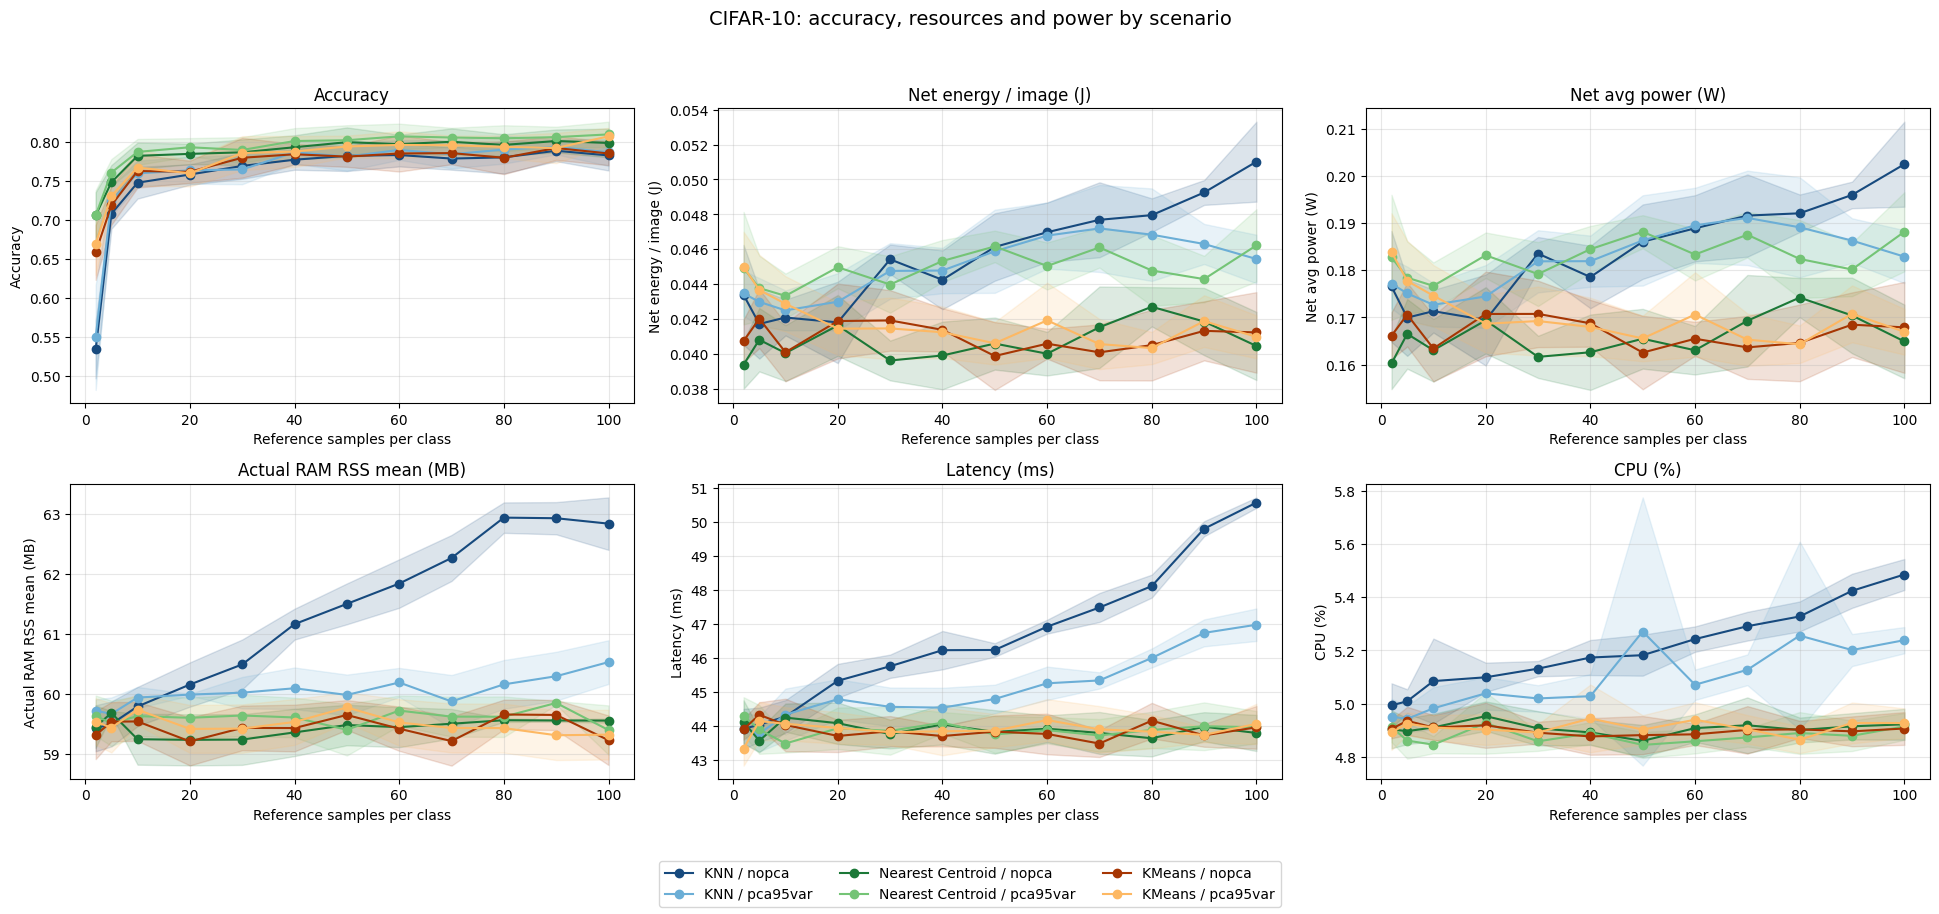

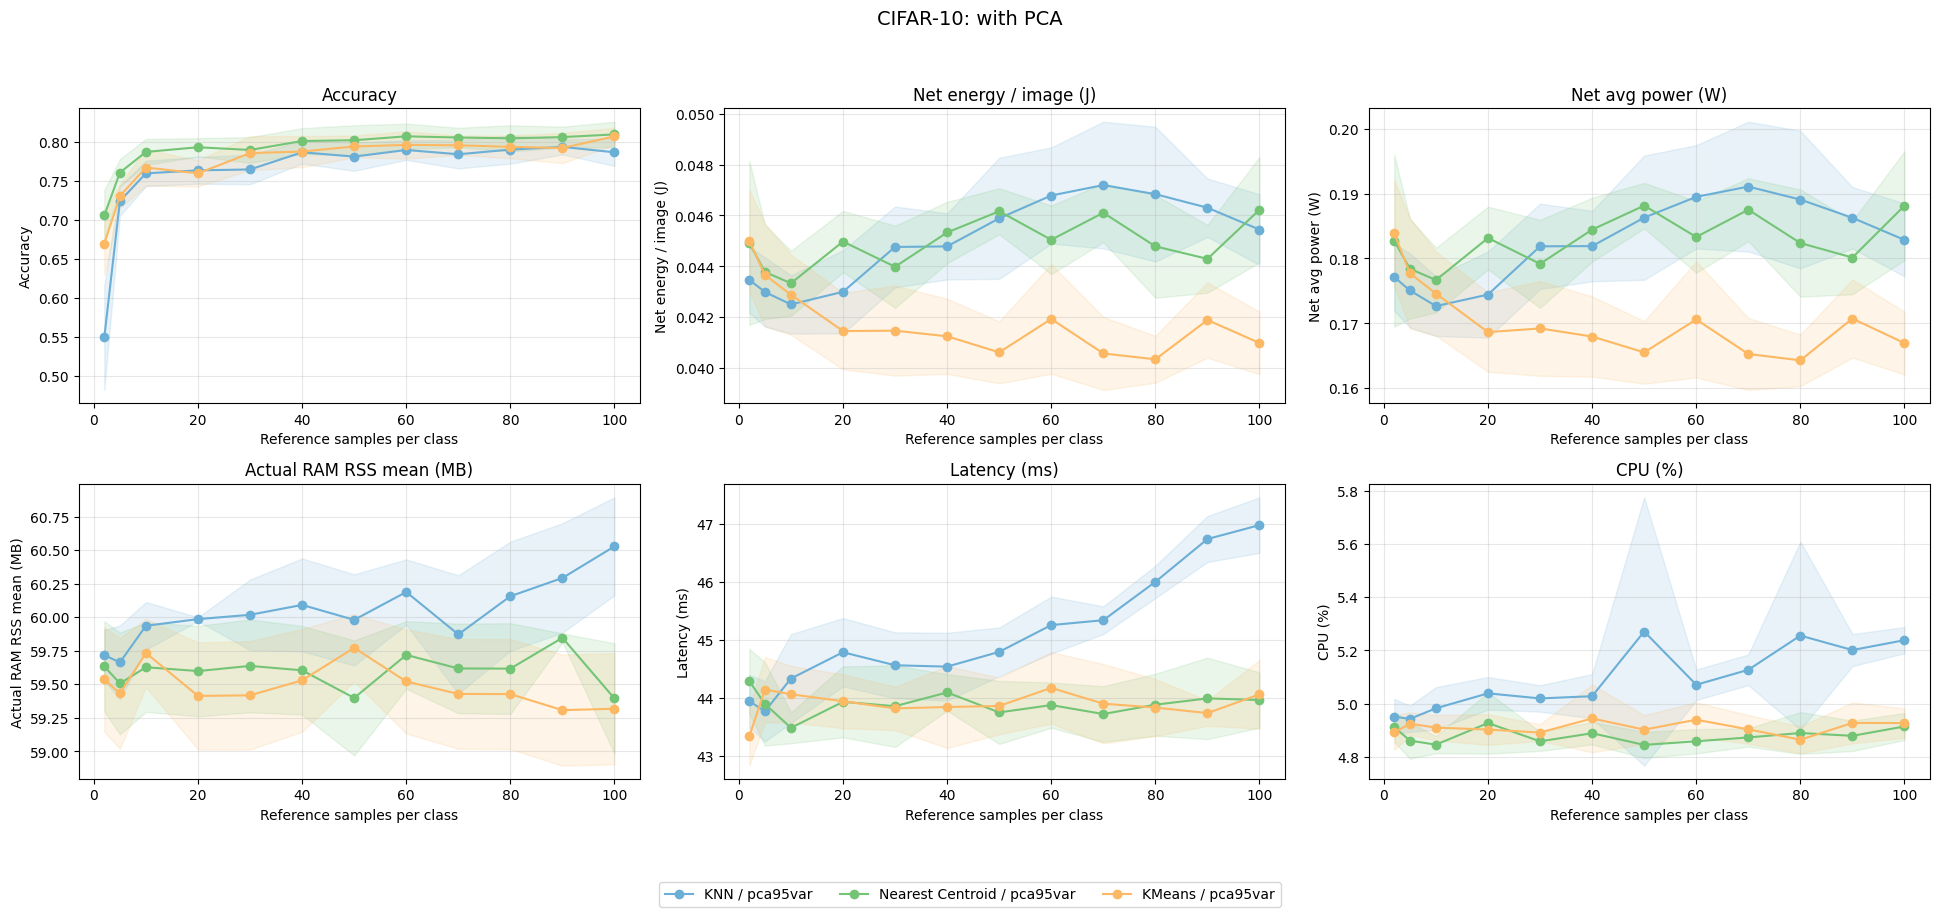

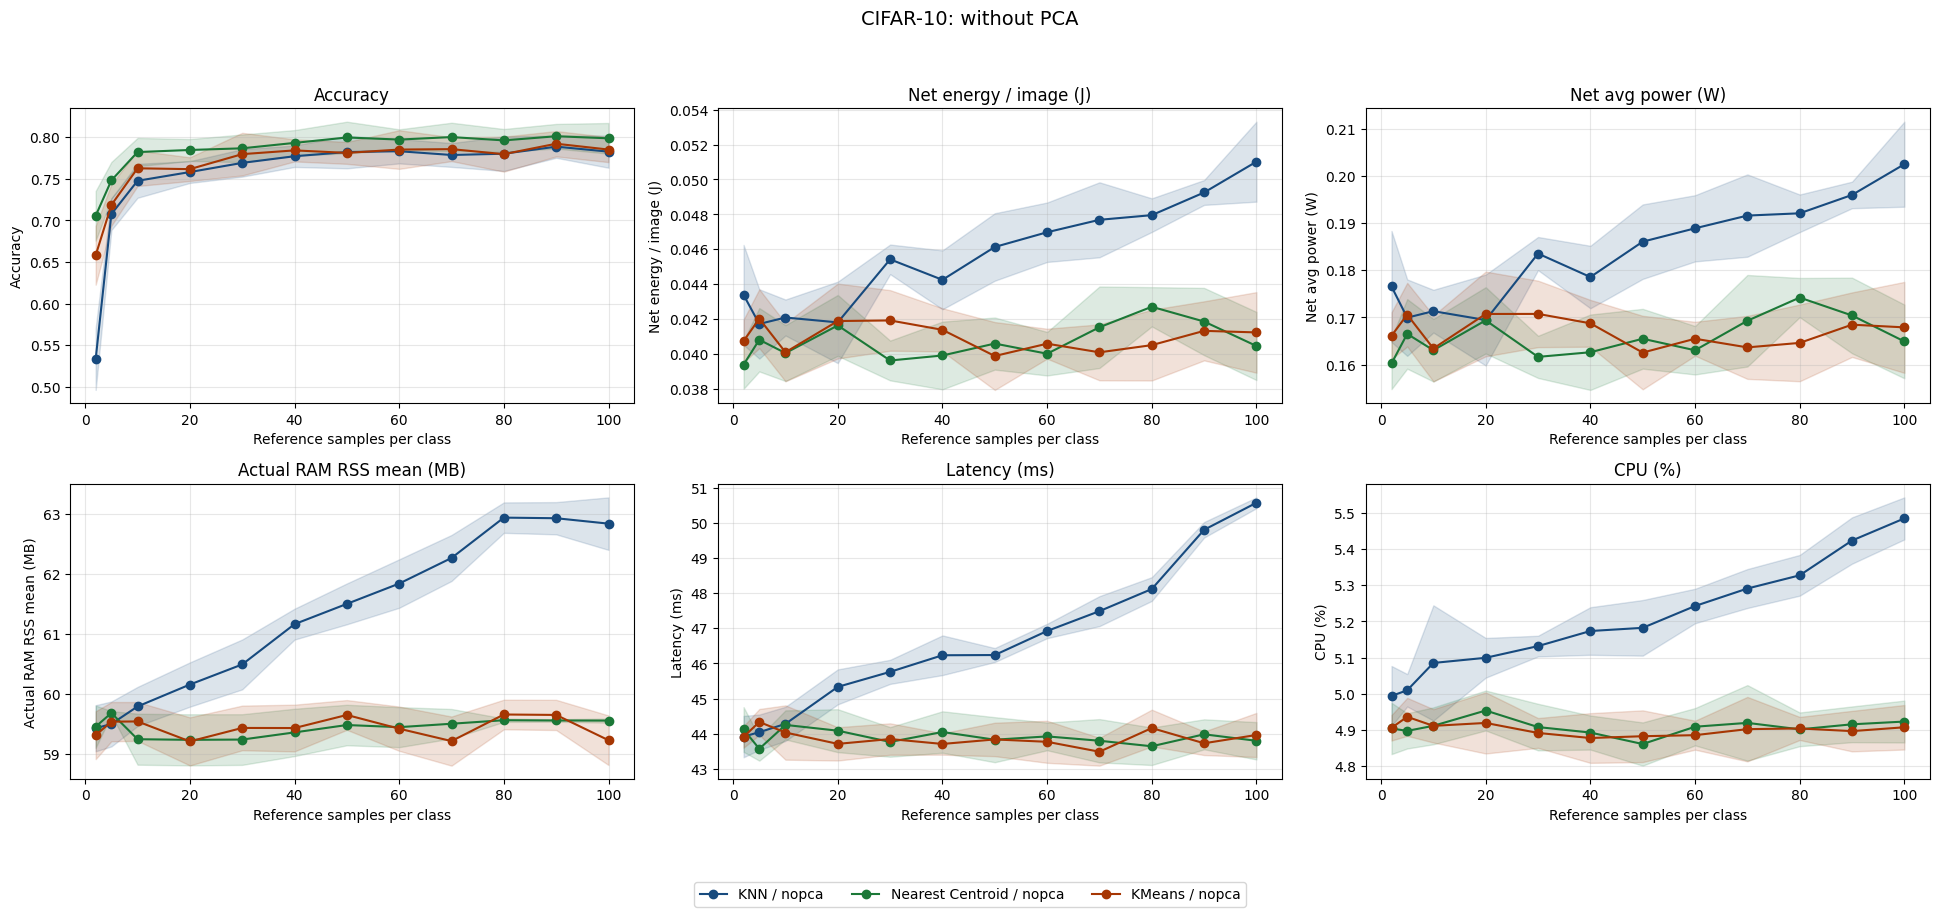

In [4]:

def order_key(label):
    clf, _, pca = label.partition(' / ')
    cidx = CLASSIFIER_ORDER.index(clf) if clf in CLASSIFIER_ORDER else len(CLASSIFIER_ORDER)
    pidx = PCA_ORDER.index(pca) if pca in PCA_ORDER else len(PCA_ORDER)
    return cidx, pidx, label

SERIES = sorted(agg['series_label'].dropna().unique(), key=order_key)

# Same classifier = same hue family; no-PCA is darker, PCA is lighter.
CLASSIFIER_PCA_COLORS = {
    ('KNN', 'nopca'): '#174A7E',
    ('KNN', 'pca'): '#6BAED6',
    ('Nearest Centroid', 'nopca'): '#1B7837',
    ('Nearest Centroid', 'pca'): '#74C476',
    ('KMeans', 'nopca'): '#A63603',
    ('KMeans', 'pca'): '#FDB863',
}

def color_for_series(label):
    classifier, _, pca = label.partition(' / ')
    pca_group = 'nopca' if pca == 'nopca' else 'pca'
    return CLASSIFIER_PCA_COLORS.get((classifier, pca_group), '#7f7f7f')

COLORS = {label: color_for_series(label) for label in SERIES}


def plot_metric_grid(metric_specs, filename, title):
    n = len(metric_specs)
    cols = 2 if n <= 4 else 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6.5 * cols, 4.6 * rows), squeeze=False)
    for ax, (metric, ylabel) in zip(axes.ravel(), metric_specs):
        for label in SERIES:
            sub = agg[agg['series_label'] == label].sort_values('samples_per_class')
            if sub.empty or f'{metric}_mean' not in sub:
                continue
            y = sub[f'{metric}_mean'].to_numpy(dtype=float)
            if np.all(np.isnan(y)):
                continue
            x = sub['samples_per_class'].to_numpy(dtype=float)
            ci_col = f'{metric}_ci95'
            ci = np.nan_to_num(sub[ci_col].to_numpy(dtype=float), nan=0.0) if ci_col in sub else 0.0
            line, = ax.plot(x, y, marker='o', label=label, color=COLORS[label])
            ax.fill_between(x, y - ci, y + ci, alpha=0.15, color=line.get_color())
        ax.set_xlabel('Reference samples per class')
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.grid(alpha=0.3)
    for ax in axes.ravel()[len(metric_specs):]:
        ax.axis('off')
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=min(3, max(1, len(labels))))
    fig.suptitle(title, fontsize=14)
    fig.tight_layout(rect=[0, 0.08, 1, 0.95])
    out = FIG_DIR / filename
    fig.savefig(out, dpi=150)
    print('saved:', out.relative_to(NB_DIR))
    return fig


metric_grid = [
    ('accuracy', 'Accuracy'),
    ('net_energy_per_image_J', 'Net energy / image (J)'),
    ('net_avg_power_W', 'Net avg power (W)'),
    ('memory_rss_mb_mean', 'Actual RAM RSS mean (MB)'),
    ('latency_ms_mean', 'Latency (ms)'),
    ('cpu_percent_mean', 'CPU (%)'),
]
plot_metric_grid(metric_grid, f'{EXPORT_SLUG}_summary_grid.png', f'{DATASET_TITLE}: accuracy, resources and power by scenario')

# PDF section 1.6.5 asks for result graphs per dataset once with PCA and once without PCA.
for pca_value, suffix, label in [(True, 'with_pca', 'with PCA'), (False, 'without_pca', 'without PCA')]:
    sub_agg = agg[agg['pca_enabled'] == pca_value].copy()
    if sub_agg.empty:
        print(f'No {label} runs available for {DATASET_TITLE}; split grid skipped.')
        continue
    old_agg = agg
    old_series = SERIES
    try:
        agg = sub_agg
        SERIES = sorted(agg['series_label'].dropna().unique(), key=order_key)
        plot_metric_grid(metric_grid, f'{EXPORT_SLUG}_{suffix}_grid.png', f'{DATASET_TITLE}: {label}')
    finally:
        agg = old_agg
        SERIES = old_series
plt.show()


### Net Energy vs Reference-Sample Count (per classifier)

One panel per classifier compares the two deployed pipelines — no PCA and `pca95var` — on net energy per image across the reference-sample sweep. Unlike the combined grid above (which shares one axis across every classifier/PCA series), this view isolates the PCA-versus-no-PCA energy gap for each classifier. It is the energy figure used in the report (`cifar10_energy_vs_samples.png`); shaded bands are 95% CIs across seeds.

saved: exports\cifar10\analysis_20260715_173358\figures\cifar10_energy_vs_samples.png


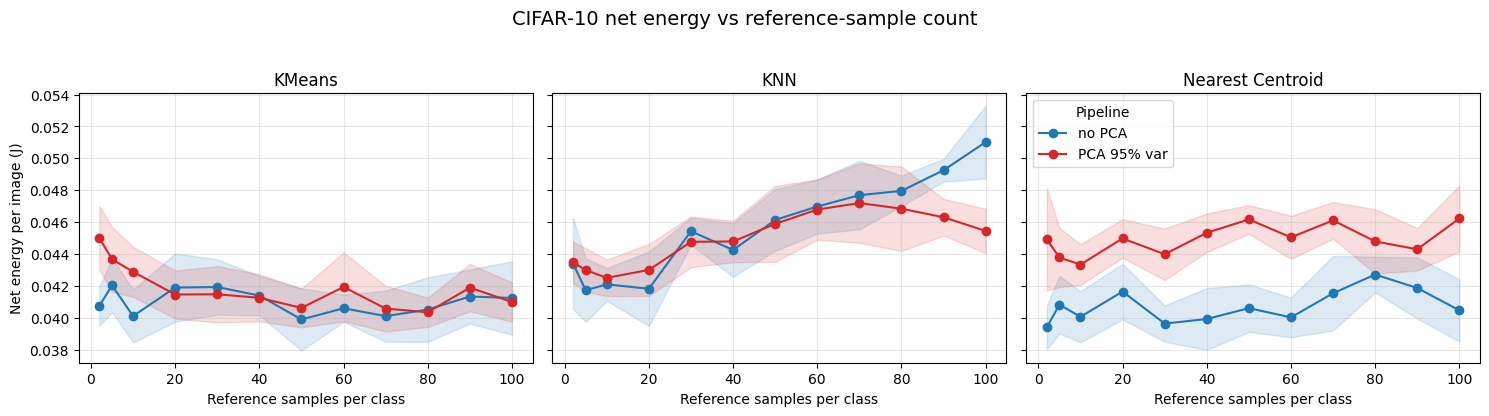

In [5]:
# Net energy per image per classifier: no-PCA vs pca95var (report energy figure).
# One panel per classifier so the two pipeline curves can be read directly,
# instead of the metric grid where every classifier/PCA series shares an axis.
ENERGY_FIG_CLASSIFIERS = ['KMeans', 'KNN', 'Nearest Centroid']
PIPELINE_STYLE = [
    ('nopca', 'no PCA', '#1f77b4'),
    ('pca95var', 'PCA 95% var', '#d62728'),
]

energy_classifiers = [c for c in ENERGY_FIG_CLASSIFIERS if c in set(agg['classifier_label'])]
fig, axes = plt.subplots(1, len(energy_classifiers),
                         figsize=(5.0 * len(energy_classifiers), 4.2),
                         squeeze=False, sharey=True)
for ax, classifier in zip(axes.ravel(), energy_classifiers):
    for pca_label, pretty, color in PIPELINE_STYLE:
        sub = agg[(agg['classifier_label'] == classifier) &
                  (agg['pca_label'] == pca_label)].sort_values('samples_per_class')
        if sub.empty:
            continue
        x = sub['samples_per_class'].to_numpy(dtype=float)
        y = sub['net_energy_per_image_J_mean'].to_numpy(dtype=float)
        ci = np.nan_to_num(sub['net_energy_per_image_J_ci95'].to_numpy(dtype=float), nan=0.0)
        ax.plot(x, y, marker='o', color=color, label=pretty)
        ax.fill_between(x, y - ci, y + ci, alpha=0.15, color=color)
    ax.set_title(classifier)
    ax.set_xlabel('Reference samples per class')
    ax.grid(alpha=0.3)
axes.ravel()[0].set_ylabel('Net energy per image (J)')
handles, labels = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(handles, labels, title='Pipeline', loc='upper left')
fig.suptitle(f'{DATASET_TITLE} net energy vs reference-sample count', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.95])
energy_fig_path = FIG_DIR / f'{EXPORT_SLUG}_energy_vs_samples.png'
fig.savefig(energy_fig_path, dpi=150)
print('saved:', energy_fig_path.relative_to(NB_DIR))
plt.show()

## 4. Sweet Spots

The practical knee uses 95% of each scenario/PCA maximum accuracy; the strict knee uses 99%. Report both because flat curves make a single magic sample count brittle.

In [6]:

def sweet_spot_table(frac):
    rows = []
    for (scenario, clf, pca), sub in agg.groupby(['scenario_name', 'classifier_label', 'pca_label']):
        sub = sub.sort_values('samples_per_class')
        acc = pd.to_numeric(sub['accuracy_mean'], errors='coerce')
        if acc.notna().sum() == 0:
            continue
        max_acc = acc.max()
        target = max_acc * frac
        reached = sub[acc >= target]
        rows.append({
            'scenario': scenario,
            'classifier': clf,
            'pca': pca,
            'max_accuracy': max_acc,
            f'spc_at_{int(frac * 100)}pct': int(reached['samples_per_class'].iloc[0]) if not reached.empty else np.nan,
            'target_accuracy': target,
        })
    return pd.DataFrame(rows).sort_values(['classifier', 'pca', 'scenario'])


sweet95 = sweet_spot_table(0.95)
sweet99 = sweet_spot_table(0.99)
print('Practical knee: first sample count reaching 95% of each scenario/PCA max accuracy')
display(sweet95.round(4))
print('Strict knee: first sample count reaching 99% of each scenario/PCA max accuracy')
display(sweet99.round(4))


Practical knee: first sample count reaching 95% of each scenario/PCA max accuracy


,scenario,classifier,pca,max_accuracy,spc_at_95pct,target_accuracy
0,scenario_cifar10_kmeans,KMeans,nopca,0.7920,10,0.7524
1,scenario_cifar10_kmeans,KMeans,pca95var,0.8070,10,0.7667
2,scenario_cifar10_knn_benchmark,KNN,nopca,0.7885,20,0.7491
3,scenario_cifar10_knn_benchmark,KNN,pca95var,0.7935,10,0.7538
4,scenario_cifar10_nearest_centroid,Nearest Centroid,nopca,0.8010,10,0.7609
5,scenario_cifar10_nearest_centroid,Nearest Centroid,pca95var,0.8095,10,0.7690


Strict knee: first sample count reaching 99% of each scenario/PCA max accuracy


,scenario,classifier,pca,max_accuracy,spc_at_99pct,target_accuracy
0,scenario_cifar10_kmeans,KMeans,nopca,0.7920,60,0.7841
1,scenario_cifar10_kmeans,KMeans,pca95var,0.8070,100,0.7989
2,scenario_cifar10_knn_benchmark,KNN,nopca,0.7885,50,0.7806
3,scenario_cifar10_knn_benchmark,KNN,pca95var,0.7935,40,0.7856
4,scenario_cifar10_nearest_centroid,Nearest Centroid,nopca,0.8010,40,0.7930
5,scenario_cifar10_nearest_centroid,Nearest Centroid,pca95var,0.8095,50,0.8014


## 5. PCA And Actual RAM Findings

PCA is evaluated with paired tests where matched no-PCA runs exist. The plot in this section uses the measured process RSS from the benchmark logs (`process_rss_mb_resource`), so it reflects actual RAM consumption on the Raspberry Pi process. The analytical vector-store numbers remain as context because they explain why KNN scales differently from centroid/prototype models.

,scenario,classifier,metric,pca_label,nopca_label,n_pairs,mean_pca,mean_nopca,mean_diff_pca_minus_nopca,wilcoxon_p
0,scenario_cifar10_kmeans,KMeans,accuracy,pca95var,nopca,120,0.77308,0.76433,0.00875,0.00009
1,scenario_cifar10_kmeans,KMeans,net_energy_per_image_J,pca95var,nopca,120,0.04184,0.04098,0.00086,0.01043
2,scenario_cifar10_knn_benchmark,KNN,accuracy,pca95var,nopca,118,0.75763,0.75072,0.00691,0.00013
3,scenario_cifar10_knn_benchmark,KNN,net_energy_per_image_J,pca95var,nopca,118,0.04503,0.04574,-0.00071,0.05779
4,scenario_cifar10_nearest_centroid,Nearest Centroid,accuracy,pca95var,nopca,120,0.78925,0.78262,0.00662,0.00001
5,scenario_cifar10_nearest_centroid,Nearest Centroid,net_energy_per_image_J,pca95var,nopca,120,0.04491,0.04072,0.00419,0.00000


Actual RAM usage from process RSS, with analytical vector-store context


,scenario_name,classifier_label,pca_label,rss_mean_mb,rss_peak_mb,rss_peak_observed_mb,raw_dim,feature_dim,pca_variance_pct,min_state_kb,max_state_kb
0,scenario_cifar10_kmeans,KMeans,nopca,59.437,59.493,59.89,160.0,160.0,NaN,18.750,18.750
1,scenario_cifar10_kmeans,KMeans,pca95var,59.487,59.543,60.02,160.0,31.0,95.141,3.633,3.633
2,scenario_cifar10_knn_benchmark,KNN,nopca,61.235,61.388,64.08,160.0,160.0,NaN,12.500,625.000
3,scenario_cifar10_knn_benchmark,KNN,pca95var,60.039,60.097,60.87,160.0,31.0,95.141,2.422,121.094
4,scenario_cifar10_nearest_centroid,Nearest Centroid,nopca,59.440,59.498,59.80,160.0,160.0,NaN,6.250,6.250
5,scenario_cifar10_nearest_centroid,Nearest Centroid,pca95var,59.600,59.659,59.97,160.0,31.0,95.141,1.211,1.211


saved: exports\cifar10\analysis_20260715_173358\figures\cifar10_actual_ram_usage.png


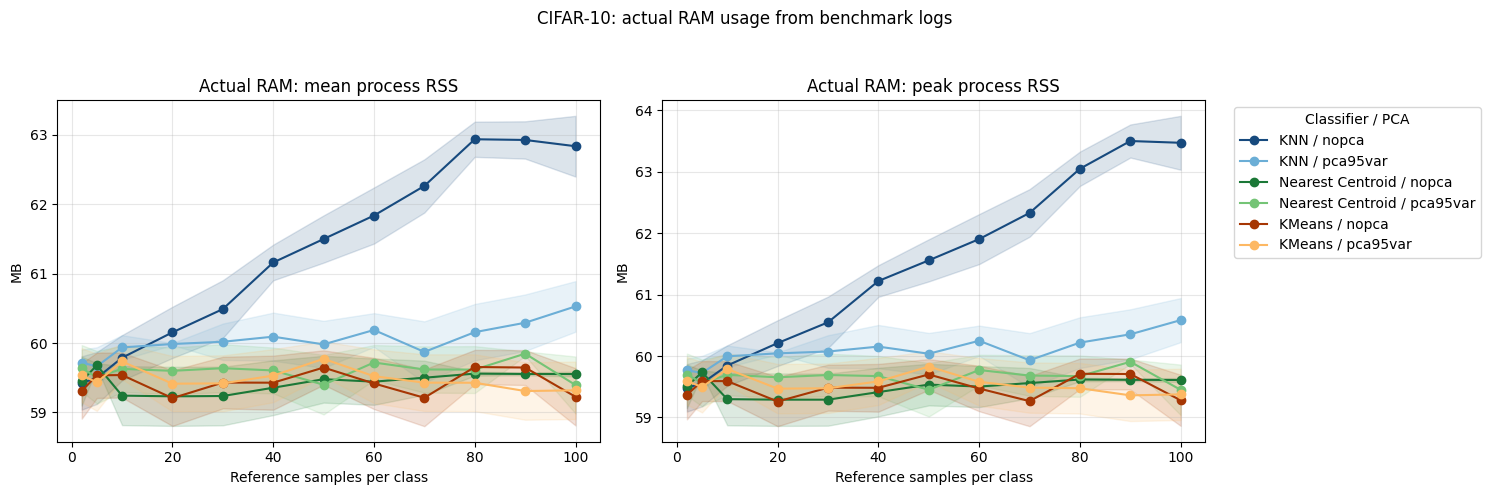

In [7]:

pca_effect_rows = []
for scenario, sub in summary.groupby('scenario_name'):
    effects = ab.pca_effect(sub)
    for metric, rec in effects.items():
        rec = dict(rec)
        rec['scenario'] = scenario
        rec['classifier'] = sub['classifier_label'].iloc[0]
        rec['metric'] = metric
        pca_effect_rows.append(rec)

pca_effect_df = pd.DataFrame(pca_effect_rows)
if pca_effect_df.empty:
    print('No matched PCA/no-PCA pairs are available for this dataset subset.')
else:
    display(pca_effect_df[['scenario', 'classifier', 'metric', 'pca_label', 'nopca_label',
                           'n_pairs', 'mean_pca', 'mean_nopca',
                           'mean_diff_pca_minus_nopca', 'wilcoxon_p']]
            .round(5))

memory_table = (summary.groupby(['scenario_name', 'classifier_label', 'pca_label'])
                    .agg(rss_mean_mb=('memory_rss_mb_mean', 'mean'),
                         rss_peak_mb=('memory_rss_mb_max', 'mean'),
                         rss_peak_observed_mb=('memory_rss_mb_max', 'max'),
                         raw_dim=('raw_feature_dim', 'median'),
                         feature_dim=('feature_dim', 'median'),
                         pca_variance_pct=('pca_explained_variance_pct', 'mean'),
                         min_state_kb=('classifier_state_kb', 'min'),
                         max_state_kb=('classifier_state_kb', 'max'))
                    .reset_index())
print('Actual RAM usage from process RSS, with analytical vector-store context')
display(memory_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for label in SERIES:
    sub = agg[agg['series_label'] == label].sort_values('samples_per_class')
    if sub.empty:
        continue
    x = sub['samples_per_class'].to_numpy(dtype=float)
    y_mean = sub['memory_rss_mb_mean_mean'].to_numpy(dtype=float)
    ci_mean = np.nan_to_num(sub.get('memory_rss_mb_mean_ci95', pd.Series(0.0, index=sub.index)).to_numpy(dtype=float), nan=0.0)
    axes[0].plot(x, y_mean, marker='o', label=label, color=COLORS[label])
    axes[0].fill_between(x, y_mean - ci_mean, y_mean + ci_mean, alpha=0.15, color=COLORS[label])

    y_peak = sub['memory_rss_mb_max_mean'].to_numpy(dtype=float)
    ci_peak = np.nan_to_num(sub.get('memory_rss_mb_max_ci95', pd.Series(0.0, index=sub.index)).to_numpy(dtype=float), nan=0.0)
    axes[1].plot(x, y_peak, marker='o', label=label, color=COLORS[label])
    axes[1].fill_between(x, y_peak - ci_peak, y_peak + ci_peak, alpha=0.15, color=COLORS[label])

axes[0].set_title('Actual RAM: mean process RSS')
axes[0].set_ylabel('MB')
axes[1].set_title('Actual RAM: peak process RSS')
axes[1].set_ylabel('MB')
for ax in axes:
    ax.set_xlabel('Reference samples per class')
    ax.grid(alpha=0.3)
axes[1].legend(title='Classifier / PCA', bbox_to_anchor=(1.04, 1), loc='upper left')
fig.suptitle(f'{DATASET_TITLE}: actual RAM usage from benchmark logs')
fig.tight_layout(rect=[0, 0, 1, 0.94])
out = FIG_DIR / f'{EXPORT_SLUG}_actual_ram_usage.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
print('saved:', out.relative_to(NB_DIR))
plt.show()


## 6. Power Boxplot

This integrates `plot_power_boxplot.py`: each box is the seed distribution of net average power for one classifier/PCA/sample-size cell. The output is written into this notebook run's dataset-specific figure folder.

718 power records after filtering/deduplication
('scenario_cifar10_kmeans', 'nopca'): ['20260701']
('scenario_cifar10_kmeans', 'pca95var'): ['20260630', '20260701']
('scenario_cifar10_knn_benchmark', 'nopca'): ['20260630', '20260701']
('scenario_cifar10_knn_benchmark', 'pca95var'): ['20260630']
('scenario_cifar10_nearest_centroid', 'nopca'): ['20260701']
('scenario_cifar10_nearest_centroid', 'pca95var'): ['20260630']


saved: exports\cifar10\analysis_20260715_173358\figures\cifar10_power_boxplot_net_avg_power_W.png


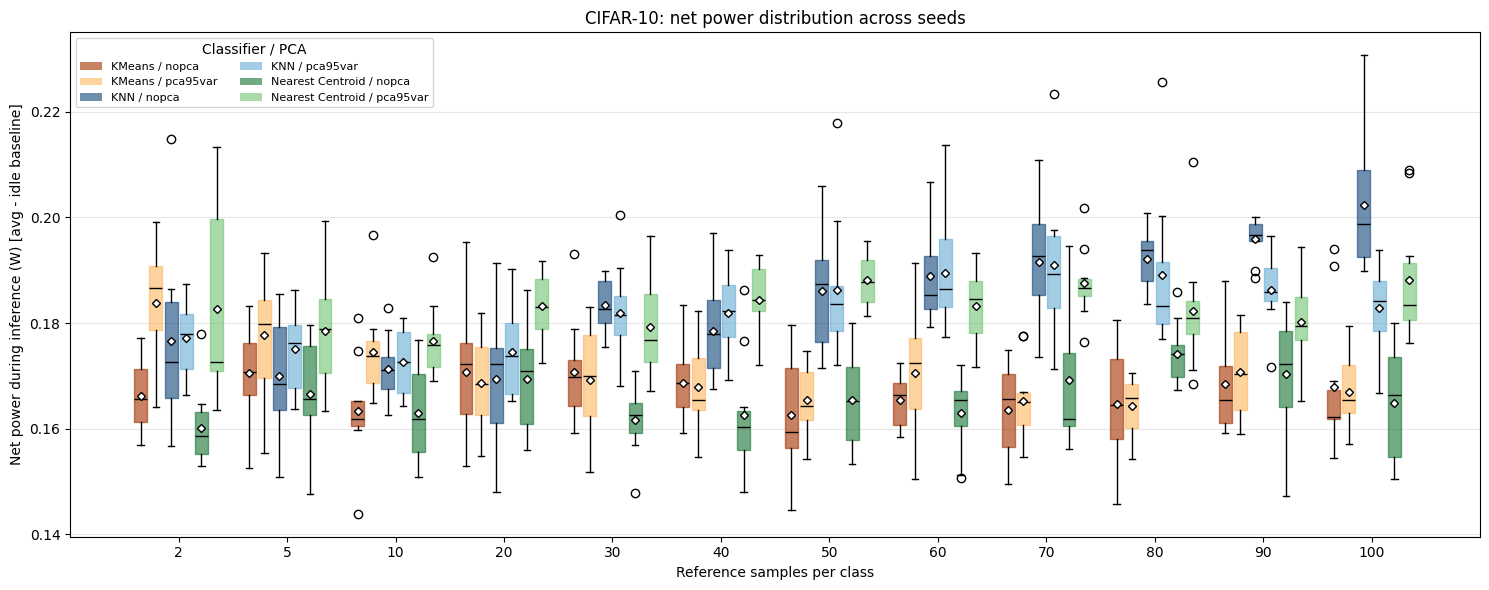

In [8]:

power_records = pbox.load_records(RESULTS_ROOT, 'net_avg_power_W')
power_records = [r for r in power_records if r.get('dataset') in DATASET_ALIASES or DATASET_NAME_PATTERN in str(r.get('scenario', '')).lower()]
power_records, power_provenance = pbox.deduplicate_records(power_records)
print(f'{len(power_records)} power records after filtering/deduplication')
for key, dates in sorted(power_provenance.items(), key=lambda item: str(item[0])):
    print(f'{key}: {dates}')

if power_records:
    fig, ax, out = pbox.plot_power_boxplot(
        power_records,
        FIG_DIR / f'{EXPORT_SLUG}_power_boxplot_net_avg_power_W.png',
        metric='net_avg_power_W',
        title=f'{DATASET_TITLE}: net power distribution across seeds',
        series_colors=COLORS,
    )
    print('saved:', out.relative_to(NB_DIR))
    plt.show()
else:
    print('No power records available for this dataset subset.')


## 7. Per-Experiment Deep Dive

Pick one `run_id` to inspect latency, cumulative accuracy, confidence and drift flags for a single run.

scenario_cifar10_kmeans/exp_121_nopca_spc2_s42 | 200 inferences | final acc: 0.625


saved: exports\cifar10\analysis_20260715_173358\figures\cifar10_deep_dive_scenario_cifar10_kmeans_exp_121_nopca_spc2_s42.png


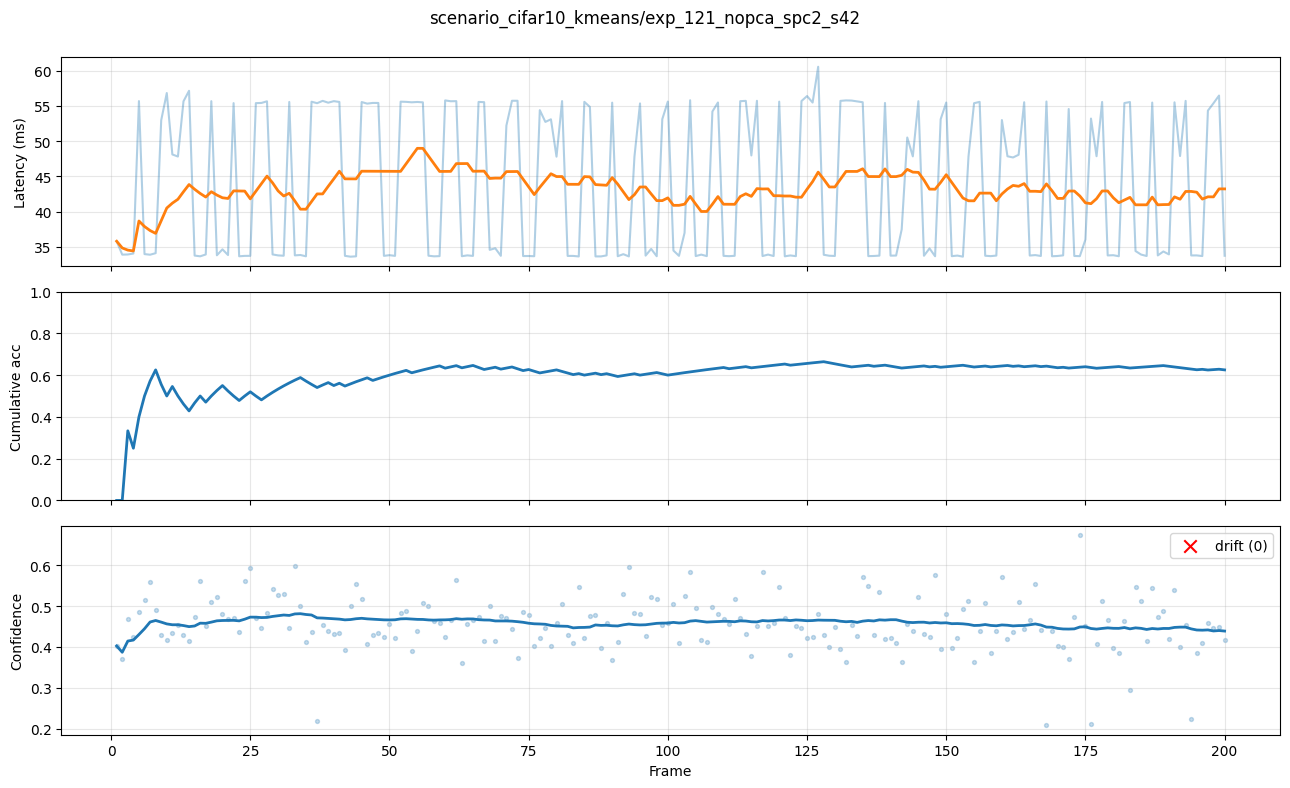

In [9]:

# Pick any row from summary['run_id'] for a detailed timeline.
EXP_RUN_ID = summary.sort_values(['scenario_name', 'samples_per_class', 'seed'])['run_id'].iloc[0]
exp_row = summary.loc[summary['run_id'] == EXP_RUN_ID].iloc[0]
exp_dir = Path(exp_row['result_dir'])
merged_path = ab._latest(exp_dir.glob('merged_analysis_*.csv'))
df = pd.read_csv(merged_path)
print(EXP_RUN_ID, '|', len(df), 'inferences | final acc:', df['final_accuracy'].dropna().iloc[-1])

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df['frame_count'], df['latency_ms'], alpha=0.35)
axes[0].plot(df['frame_count'], df['latency_ms'].rolling(20, min_periods=1).mean(), lw=2)
axes[0].set_ylabel('Latency (ms)'); axes[0].grid(alpha=0.3)
axes[1].plot(df['frame_count'], df['cumulative_accuracy'], lw=2)
axes[1].set_ylabel('Cumulative acc'); axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3)
axes[2].scatter(df['frame_count'], df['confidence'], s=8, alpha=0.25)
axes[2].plot(df['frame_count'], df['confidence'].rolling(50, min_periods=1).mean(), lw=2)
if 'drift_detected' in df:
    drift = df[ab._to_bool(df['drift_detected'])]
    axes[2].scatter(drift['frame_count'], drift['confidence'], marker='x', s=80,
                    color='red', label=f'drift ({len(drift)})')
axes[2].set_ylabel('Confidence'); axes[2].set_xlabel('Frame'); axes[2].grid(alpha=0.3); axes[2].legend()
fig.suptitle(EXP_RUN_ID); fig.tight_layout(rect=[0, 0, 1, 0.98])
out = FIG_DIR / f"{EXPORT_SLUG}_deep_dive_{EXP_RUN_ID.replace('/', '_')}.png"
fig.savefig(out, dpi=150)
print('saved:', out.relative_to(NB_DIR))
plt.show()


## 8. Export Tables, Figures And Findings

All exports go to `exports/<dataset>/analysis_<timestamp>/` so CIFAR-10 and ImageNet/Imagenette runs cannot overwrite each other.

In [10]:

summary_csv = EXPORT_DIR / f'experiment_summary_{EXPORT_SLUG}.csv'
agg_csv = EXPORT_DIR / f'aggregated_by_scenario_{EXPORT_SLUG}.csv'
sweet95_csv = EXPORT_DIR / f'sweet_spots_95pct_{EXPORT_SLUG}.csv'
sweet99_csv = EXPORT_DIR / f'sweet_spots_99pct_{EXPORT_SLUG}.csv'
pca_csv = EXPORT_DIR / f'pca_effect_{EXPORT_SLUG}.csv'
requirements_csv = EXPORT_DIR / f'project_requirements_{EXPORT_SLUG}.csv'

summary.to_csv(summary_csv, index=False)
agg.to_csv(agg_csv, index=False)
sweet95.to_csv(sweet95_csv, index=False)
sweet99.to_csv(sweet99_csv, index=False)
pca_effect_df.to_csv(pca_csv, index=False)

scenario_tbl = (summary.groupby(['scenario_name', 'classifier_label'])
                     .agg(dataset=('dataset_name', 'first'),
                          runs=('run_id', 'count'),
                          seeds=('seed', 'nunique'),
                          sample_min=('samples_per_class', 'min'),
                          sample_max=('samples_per_class', 'max'),
                          pca_modes=('pca_label', lambda s: ', '.join(sorted(s.dropna().unique()))),
                          n_images_median=('n_images', 'median'),
                          resolution=('inference_resolution', 'first'),
                          raw_dim=('raw_feature_dim', 'median'),
                          feature_dim_min=('feature_dim', 'min'),
                          feature_dim_max=('feature_dim', 'max'))
                     .reset_index())
requirements_rows = [
    {'pdf_requirement': 'Hardware', 'notebook_documentation': 'Raspberry Pi Zero 2W with external power supply / Voltcraft DSP-3005 at 5 V; power logs are integrated per experiment.'},
    {'pdf_requirement': 'Model task', 'notebook_documentation': 'Image classification benchmark on novelty/test images.'},
    {'pdf_requirement': 'Used image dataset(s)', 'notebook_documentation': ', '.join(sorted(summary['dataset_name'].dropna().unique()))},
    {'pdf_requirement': 'Used models / inference pipelines', 'notebook_documentation': ', '.join(sorted(summary['classifier_label'].dropna().unique()))},
    {'pdf_requirement': 'PCA and no-PCA variants', 'notebook_documentation': ', '.join(sorted(summary['pca_label'].dropna().unique()))},
    {'pdf_requirement': 'Reference samples sweep', 'notebook_documentation': f"{int(summary['samples_per_class'].min())}..{int(summary['samples_per_class'].max())} samples/class; values: {sorted(summary['samples_per_class'].dropna().unique().astype(int).tolist())}"},
    {'pdf_requirement': 'Experimental metrics collected', 'notebook_documentation': 'Accuracy, RSS memory, analytical classifier/reference-store memory, CPU, latency, gross/net energy and power.'},
    {'pdf_requirement': 'How metrics are collected', 'notebook_documentation': 'Accuracy/latency/CPU/RSS from merged/resource logs; power/energy from external supply metadata; net values subtract idle baseline.'},
    {'pdf_requirement': 'Training process', 'notebook_documentation': 'Scenario pipelines are trained on the full training split; benchmark varies only initialization sample size.'},
    {'pdf_requirement': 'Seeds', 'notebook_documentation': f"Initialization/test-order seeds present: {sorted(summary['seed'].dropna().unique().astype(int).tolist())}"},
    {'pdf_requirement': 'Train/test size', 'notebook_documentation': f"Median benchmark test images per run: {int(summary['n_images'].median())}; training split is the scenario training set used by the TinyMLOps retrainer."},
    {'pdf_requirement': 'PCA explained variance', 'notebook_documentation': ', '.join(f"{k}: {v:.2f}%" for k, v in summary.dropna(subset=['pca_explained_variance_pct']).groupby('pca_label')['pca_explained_variance_pct'].mean().items()) or 'No PCA variance available.'},
    {'pdf_requirement': 'Averaging/statistical tests', 'notebook_documentation': 'Means, std and 95% CI across seeds; paired Wilcoxon PCA vs no-PCA where matched pairs exist.'},
    {'pdf_requirement': 'Expected graphs per dataset', 'notebook_documentation': 'Combined grid plus split grids with PCA and without PCA; power distribution boxplot integrated.'},
]
requirements_df = pd.DataFrame(requirements_rows)
requirements_df.to_csv(requirements_csv, index=False)

best_rows = (agg.sort_values('accuracy_mean')
               .groupby(['classifier_label', 'pca_label'], as_index=False)
               .tail(1)
               .sort_values(['classifier_label', 'pca_label']))
energy_rows = (summary.groupby(['classifier_label', 'pca_label'])
                     .agg(net_power_W=('net_avg_power_W', 'mean'),
                          net_energy_J_img=('net_energy_per_image_J', 'mean'),
                          net_charge_mAh_run=('net_charge_run_mAh', 'mean'),
                          memory_rss_mb=('memory_rss_mb_mean', 'mean'),
                          memory_peak_mb=('memory_rss_mb_max', 'mean'),
                          latency_ms=('latency_ms_mean', 'mean'),
                          cpu_pct=('cpu_percent_mean', 'mean'))
                     .reset_index())


def _markdown_table(df):
    df = df.copy().fillna('')
    cols = [str(c) for c in df.columns]
    lines = ['| ' + ' | '.join(cols) + ' |',
             '| ' + ' | '.join(['---'] * len(cols)) + ' |']
    for _, row in df.iterrows():
        vals = [str(row[c]).replace('\n', ' ') for c in df.columns]
        lines.append('| ' + ' | '.join(vals) + ' |')
    return '\n'.join(lines)

findings = []
findings.append(f'# {DATASET_TITLE} Benchmark Findings')
findings.append('')
findings.append(f'- Completed experiments analyzed: {len(summary)}')
findings.append(f'- Scenarios: {", ".join(sorted(summary["scenario_name"].dropna().unique()))}')
findings.append(f'- Export folder: `{EXPORT_DIR.relative_to(NB_DIR)}`')
findings.append('')
findings.append('## Project/PDF requirements coverage')
findings.append(_markdown_table(requirements_df))
findings.append('')
findings.append('## Scenario coverage')
findings.append(_markdown_table(scenario_tbl.round(3)))
findings.append('')
findings.append('## Project alignment')
findings.append('- The analysis follows `01 knn-sweet-spot-1.pdf`: identify the KNN/reference-sample sweet spot, document PCA usefulness, and compare KNN with sample-based alternatives under TinyMLOps resource constraints.')
findings.append('- Findings are reported per scenario/classifier so KNN, Nearest Centroid, and KMeans are not averaged into one ambiguous line.')
findings.append('- Power is shown both as net energy/charge summaries and as the required seed-distribution boxplot.')
findings.append('- The figure set includes combined views plus separate with-PCA and without-PCA grids per analyzed dataset family.')
findings.append('')
findings.append('## Accuracy knees')
findings.append(_markdown_table(sweet95.round(4)))
findings.append('')
findings.append('## Best observed mean accuracy per classifier/PCA')
findings.append(_markdown_table(best_rows[['classifier_label', 'pca_label', 'samples_per_class', 'accuracy_mean', 'accuracy_ci95']].round(4)))
findings.append('')
findings.append('## PCA effect')
if pca_effect_df.empty:
    findings.append('No matched PCA/no-PCA pairs are available in this subset; PCA claims are therefore limited to dimensionality and resource footprint.')
else:
    findings.append(_markdown_table(pca_effect_df[['scenario', 'classifier', 'metric', 'n_pairs', 'mean_pca', 'mean_nopca', 'mean_diff_pca_minus_nopca', 'wilcoxon_p']].round(5)))
findings.append('')
findings.append('## Power and resource summary')
findings.append(_markdown_table(energy_rows.round(4)))
findings.append('')
findings.append('## Figures')
for p in sorted(FIG_DIR.glob('*.png')):
    findings.append(f'- `{p.relative_to(EXPORT_DIR)}`')

findings_md = EXPORT_DIR / f'findings_{EXPORT_SLUG}.md'
findings_md.write_text('\n'.join(findings), encoding='utf-8')

print('Wrote:')
for p in [summary_csv, agg_csv, sweet95_csv, sweet99_csv, pca_csv, requirements_csv, findings_md]:
    print(' ', p.relative_to(NB_DIR), f'({p.stat().st_size / 1024:.1f} KB)')
print(' Figures:', FIG_DIR.relative_to(NB_DIR))


Wrote:


  exports\cifar10\analysis_20260715_173358\experiment_summary_cifar10.csv (403.5 KB)
  exports\cifar10\analysis_20260715_173358\aggregated_by_scenario_cifar10.csv (44.2 KB)
  exports\cifar10\analysis_20260715_173358\sweet_spots_95pct_cifar10.csv (0.5 KB)
  exports\cifar10\analysis_20260715_173358\sweet_spots_99pct_cifar10.csv (0.5 KB)
  exports\cifar10\analysis_20260715_173358\pca_effect_cifar10.csv (1.0 KB)
  exports\cifar10\analysis_20260715_173358\project_requirements_cifar10.csv (1.4 KB)
  exports\cifar10\analysis_20260715_173358\findings_cifar10.md (5.9 KB)
 Figures: exports\cifar10\analysis_20260715_173358\figures
